In [ ]:
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid as integrate
from scipy.stats import norm
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [ ]:
LOG_FILE = "240069lab9_gyro.csv"
WHEEL_R  = 0.043   # wheel radius, m (D = 8.6 cm)
WHEEL_L  = 0.198   # distance between wheels, m
TAPE_DEG = None    # tape-mark angle after the run, deg (left/CCW = +), e.g. -135

if not os.path.exists(LOG_FILE):
    from google.colab import files
    files.upload()

In [ ]:
#loading log
df = pd.read_csv(LOG_FILE, skipinitialspace=True)
df.columns = df.columns.str.strip()
df["phase"] = df["phase"].astype(str).str.strip()

#removing repeated gyro samples:
n_before = len(df)
df = df[df.t_us.diff() != 0].reset_index(drop=True)

#finding the unit of t_us and convert to seconds
unit_ms = np.polyfit(df.t_us - df.t_us[0], df.t_ms - df.t_ms[0], 1)[0]

if abs(unit_ms - 0.001) < 0.0001:
    df["t"] = (df.t_us - df.t_us[0]) * 1e-6        #t_us really is µs
elif abs(unit_ms - 0.256) < 0.02:
    df["t"] = (df.t_us - df.t_us[0]) * 256e-6      #t_us counts 256 µs steps
else:
    df["t"] = (df.t_ms - df.t_ms[0]) / 1000        #back to the clock
FS = 1 / np.median(np.diff(df.t))                  #samples per second
print(f"one t_us step = {unit_ms:.4f} ms; {n_before - len(df)} repeated rows removed")
print(f"{len(df)} samples in {df.t.iloc[-1]:.0f} s, one every {1000 / FS:.0f} ms ({FS:.1f} Hz)")

#heading from the wheels (the reference) and its rate
df["th_enc"] = WHEEL_R / WHEEL_L * (df.encR - df.encL)
window = max(5, int(round(0.3 * FS)) | 1)                 #smooth over ~0.3 s
df["w_enc"] = savgol_filter(df.th_enc, window, 2, deriv=1, delta=1 / FS)

#K from raw to deg/s. Using rate which is steady and not clipped
raw = df.gz_raw.to_numpy(float)
cal = df.gz_cal.to_numpy(float) / 1000
jump_before = np.abs(np.diff(raw, prepend=raw[0]))
jump_after = np.abs(np.diff(raw, append=raw[-1]))
steady = (np.abs(raw) < 32000) & (jump_before < 0.02 * np.abs(raw) + 30) & (jump_after < 0.02 * np.abs(raw) + 30)
K = np.polyfit(raw[steady], cal[steady], 1)[0]

#sign: does the raw gyro go up when the wheels say "turning left"?
turning = df.phase.isin(["sin", "rect"]).to_numpy()
SIGN = 1 if np.corrcoef(raw[turning], df.w_enc[turning])[0, 1] > 0 else -1
POS_DIR = "CCW" if SIGN > 0 else "CW"
df["w"] = SIGN * K * raw                                  #gyro rate, deg/s, left = +

static = df[df.phase == "static"].copy()
static["t"] -= static.t.iloc[0]                           #still part, time from 0
rot = df[df.index > static.index[-1]].copy()              #everything after it

print(f"K = {K:.6f} deg/s per raw unit; positive raw = {POS_DIR}")

parts = df.groupby((df.phase != df.phase.shift()).cumsum())

print(parts.agg(phase=("phase", "first"), samples=("t", "size"), start_s=("t", "first"), end_s=("t", "last")).round(1).to_string(index=False))

one t_us step = 0.2560 ms; 0 repeated rows removed
3934 samples in 261 s, one every 62 ms (16.0 Hz)
K = 0.008749 deg/s per raw unit; positive raw = CCW
   phase  samples  start_s  end_s
  static     2711      0.0  180.0
    rest       46    180.1  183.0
     sin      540    183.1  219.0
    rest       46    219.1  222.1
    rect      544    222.1  258.1
rest_end       47    258.1  261.1


b0 (first 30 s) = +0.4681 ± 0.0032deg/s
  first  1 s: b0 = +0.5058
  first  2 s: b0 = +0.4820
  first  5 s: b0 = +0.4632
  first 10 s: b0 = +0.4660
  first 20 s: b0 = +0.4640
  first 30 s: b0 = +0.4681
T_CAL = 30 s, leaves 1.20 deg/min; calibrate_gyro = +0.4681 deg/s
test on turning data (should be None): None


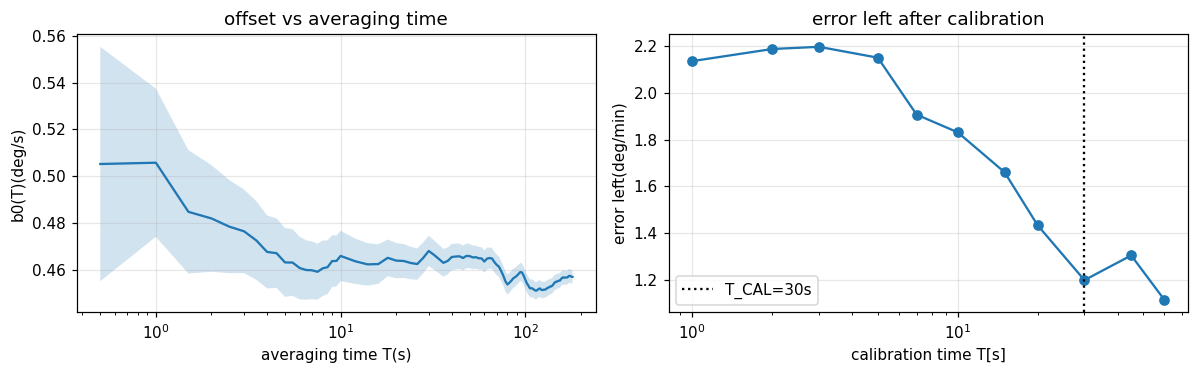

In [ ]:
#offset and my calibration

first30 = static.w[static.t < 30]
b0_30 = first30.mean()
se_30 = first30.std() / np.sqrt(len(first30))             #standard error

print(f"b0 (first 30 s) = {b0_30:+.4f} ± {se_30:.4f}deg/s")
for T in [1, 2, 5, 10, 20, 30]:
    print(f"  first {T:2d} s: b0 = {static.w[static.t < T].mean():+.4f}")

NOISE_STILL = 1.4826 * np.median(np.abs(static.w - static.w.median()))   #normal spread when still

def calibrate_gyro(log, T_cal=None, where="first"):
    """Offset b0 [deg/s] from still data (columns t, w). Returns None if the robot moved."""

    T_cal = T_CAL if T_cal is None else T_cal
    t, w = log.t.to_numpy(), log.w.to_numpy()
    x = w[t <= t[0] + T_cal] if where == "first" else w[t >= t[-1] - T_cal]
    mid = np.median(x)

    spread = 1.4826 * np.median(np.abs(x - mid))

    if spread > 2 * NOISE_STILL:
        return None                                       #robot moved
    return x[np.abs(x - mid) <= 4 * max(spread, 1e-9)].mean()   #average without spikes

def error_left(T):
    """Heading error per minute [deg/min] left after calibrating for T seconds."""
    errors = []

    for start in np.arange(0, static.t.iloc[-1] - T - 60, 5):
        b = calibrate_gyro(static[static.t >= start], T)

        if b is None:
            continue

        true_next_minute = static.w[(static.t >= start + T) & (static.t < start + T + 60)].mean()
        errors.append(b - true_next_minute)

    return 60 * np.sqrt(np.mean(np.square(errors)))

T_list = [1, 2, 3, 5, 7, 10, 15, 20, 30, 45, 60]
err_list = [error_left(T) for T in T_list]
T_CAL = next(T for T, e in zip(T_list, err_list) if e <= 1.1 * min(err_list))
ERR_LEFT = err_list[T_list.index(T_CAL)]
b0_cal = calibrate_gyro(static)

print(f"T_CAL = {T_CAL} s, leaves {ERR_LEFT:.2f} deg/min; calibrate_gyro = {b0_cal:+.4f} deg/s")
print("test on turning data (should be None):", calibrate_gyro(rot[rot.phase == "sin"]))


fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
T_fine = np.unique(np.r_[np.arange(0.5, 10, 0.5), np.arange(10, 181, 2)])
b0_T = np.array([static.w[static.t < T].mean() for T in T_fine])
se_T = np.array([static.w[static.t < T].std() / np.sqrt((static.t < T).sum()) for T in T_fine])
ax[0].fill_between(T_fine, b0_T - 2 * se_T, b0_T + 2 * se_T, alpha=0.2)
ax[0].plot(T_fine, b0_T)
ax[0].set(xscale="log", xlabel="averaging time T(s)", ylabel="b0(T)(deg/s)", title="offset vs averaging time")
ax[1].plot(T_list, err_list, "o-")
ax[1].axvline(T_CAL, c="k", ls=":", label=f"T_CAL={T_CAL}s")
ax[1].set(xscale="log", xlabel="calibration time T[s]", ylabel="error left(deg/min)", title="error left after calibration")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
#My gyro’s offset settles at about 0.47 deg/s after 10 s of averaging.
#A 30-second calibration leaves only 1.2° of heading error per minute, and calibrating longer hardly helps, so I use 30 s

30-s means: [0.4681 0.4592 0.4454 0.4359 0.4682 0.4657] → d = +0.0003 deg/s per min
(a) heading drift without correction: +27.2 deg/min (b0·60 = +28.1)
(b) error after 1, 2, 3 min with b0 removed: [-0.29 -1.91 -1.98] deg


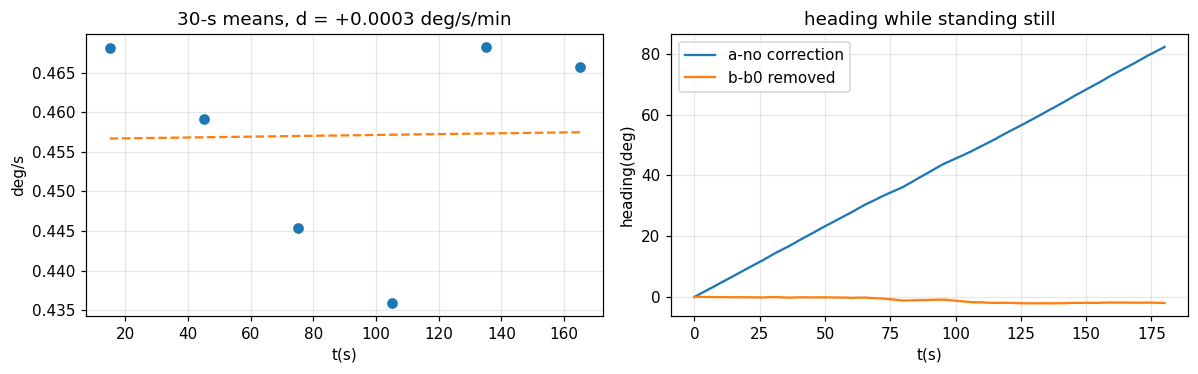

In [ ]:
#Finding whether offset change during 3 minutes (Avg every 30s and a fit line)

centres = np.arange(15, 180, 30)                          #middle of each 30-s window
means = np.array([static.w[(static.t >= c - 15) & (static.t < c + 15)].mean() for c in centres])
d = np.polyfit(centres / 60, means, 1)[0]                 #deg/s per minute
heading_raw = integrate(static.w, static.t, initial=0)            #no correction
heading_fixed = integrate(static.w - b0_30, static.t, initial=0)  #offset removed
HEAD_DRIFT = np.polyfit(static.t / 60, heading_raw, 1)[0]

print("30-s means:", means.round(4), f"→ d = {d:+.4f} deg/s per min")
print(f"(a) heading drift without correction: {HEAD_DRIFT:+.1f} deg/min (b0·60 = {60 * b0_30:+.1f})")
print("(b) error after 1, 2, 3 min with b0 removed:", np.interp([60, 120, 180], static.t, heading_fixed).round(2), "deg")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].plot(centres, means, "o")
ax[0].plot(centres, np.polyval(np.polyfit(centres, means, 1), centres), "--")
ax[0].set(xlabel="t(s)", ylabel="deg/s", title=f"30-s means, d = {d:+.4f} deg/s/min")
ax[1].plot(static.t, heading_raw, label="a-no correction")
ax[1].plot(static.t, heading_fixed, label="b-b0 removed")
ax[1].set(xlabel="t(s)", ylabel="heading(deg)", title="heading while standing still")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
#While the robot stood still, the gyro still showed a small turning rate (about 0.47 deg/s)
#this value stayed almost the same for all 3 minutes. If I don't correct it
#the gyro 'thinks' the robot turned 27° every minute even though it didn't move
#After subtracting that value, the error is only 2° after 3 minutes."

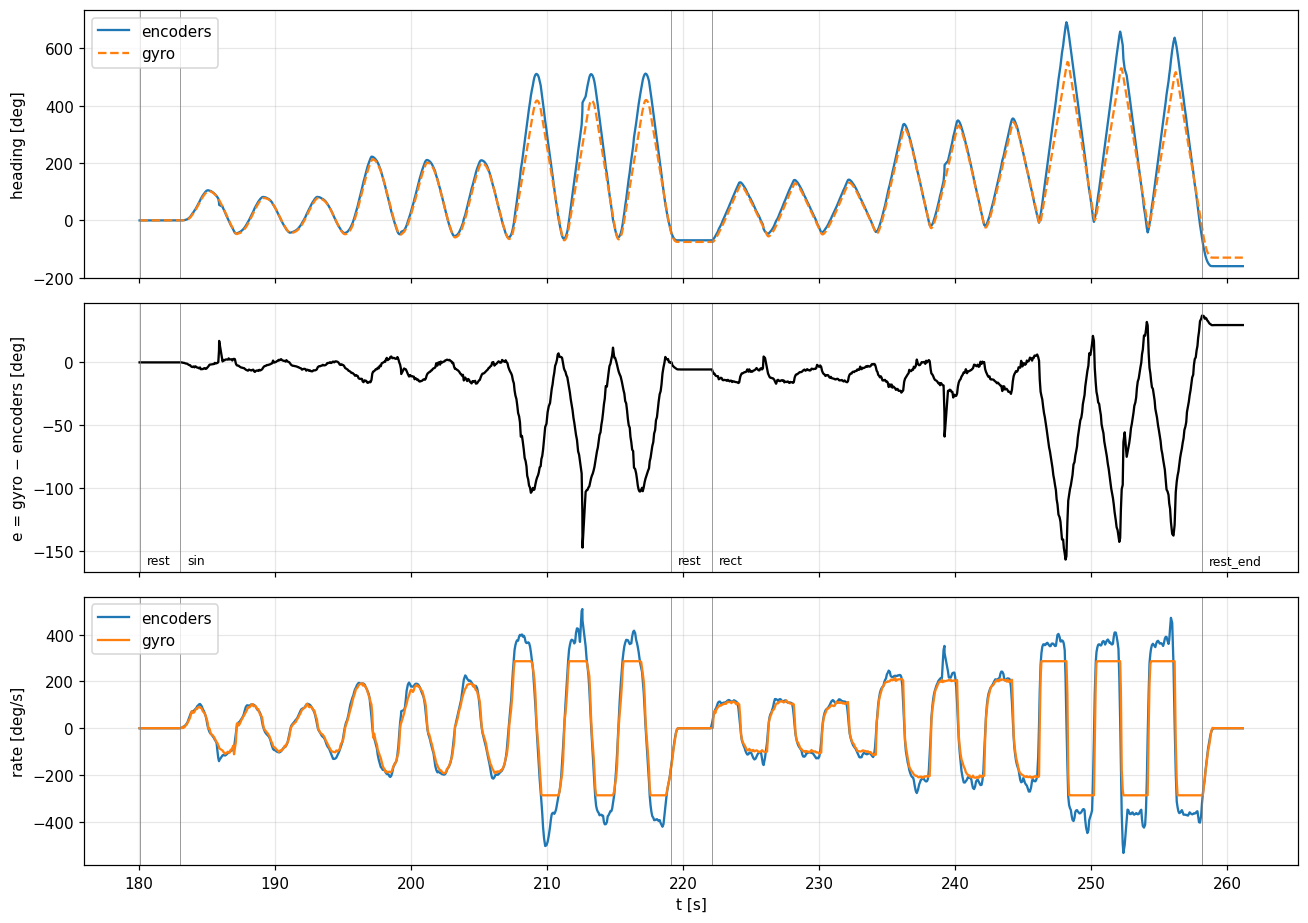

     part  turned [deg]  e change [deg]
     rest           0.0            -0.0
  sin 30%         756.6            -2.2
  sin 60%        1586.2             3.2
 sin 150%        3396.8             1.0
     rest          34.3            -5.1
 rect 30%        1113.0             4.0
 rect 60%        2196.9             7.9
rect 150%        4114.3            33.3
 rest_end          97.9            -7.5

b0 fresh +0.4657, b0 from start +0.4681, real offset after the run +0.4705 deg/s
final heading: encoders -159.4, gyro -129.7 (with old b0 -129.9) deg


In [ ]:
#gyro vs encoders

b0_fresh = calibrate_gyro(static, where="last")           #right before the run
rot["th_g"] = integrate(rot.w - b0_fresh, rot.t, initial=0)
rot["th_g_old"] = integrate(rot.w - b0_cal, rot.t, initial=0)
rot["th_e"] = rot.th_enc - rot.th_enc.iloc[0]
rot["e"] = rot.th_g - rot.th_e                            #gyro minus encoders

fig, ax = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)

ax[0].plot(rot.t, rot.th_e, label="encoders")
ax[0].plot(rot.t, rot.th_g, "--", label="gyro")
ax[0].set_ylabel("heading [deg]"); ax[0].legend()
ax[1].plot(rot.t, rot.e, "k"); ax[1].set_ylabel("e = gyro − encoders [deg]")
ax[2].plot(rot.t, rot.w_enc, label="encoders")
ax[2].plot(rot.t, rot.w, label="gyro")
ax[2].set(ylabel="rate [deg/s]", xlabel="t [s]"); ax[2].legend()

for _, g in rot.groupby((rot.phase != rot.phase.shift()).cumsum()):       #phase borders
    for a in ax:
        a.axvline(g.t.iloc[0], c="grey", lw=0.5)
    ax[1].text(g.t.iloc[0] + 0.5, 0.03, g.phase.iloc[0], transform=ax[1].get_xaxis_transform(), fontsize=8)
plt.tight_layout(); plt.show()

#how much e changes in each part of the run
rows = []

for (_, phase, amp), g in rot.groupby([(rot.phase != rot.phase.shift()).cumsum(), "phase", "amp"]):
    rows.append([f"{phase} {amp}%" if amp else phase, np.abs(np.diff(g.th_e)).sum(), g.e.iloc[-1] - g.e.iloc[0]])

print(pd.DataFrame(rows, columns=["part", "turned [deg]", "e change [deg]"]).round(1).to_string(index=False))

after = rot[rot.t > rot.t.iloc[-1] - 2]                   #last 2s, robot still

print(f"\nb0 fresh {b0_fresh:+.4f}, b0 from start {b0_cal:+.4f}, real offset after the run {after.w.mean():+.4f} deg/s")
print(f"final heading: encoders {rot.th_e.iloc[-1]:+.1f}, gyro {rot.th_g.iloc[-1]:+.1f} (with old b0 {rot.th_g_old.iloc[-1]:+.1f}) deg")

if TAPE_DEG is not None:
    print(f"tape mark {TAPE_DEG:+.1f} deg → gyro off by {rot.th_g.iloc[-1] - TAPE_DEG:+.1f}, encoders off by {rot.th_e.iloc[-1] - TAPE_DEG:+.1f}")

In [ ]:
#At slow and medium speeds the gyro and the wheels agree.
#Almost all of the 30° difference at the end comes from the fastest turns, where the gyro hits its limit and misses part of each turn.

range +286.7 / -286.4 deg/s (raw 32764 / -32736): reached, the gyro clipped


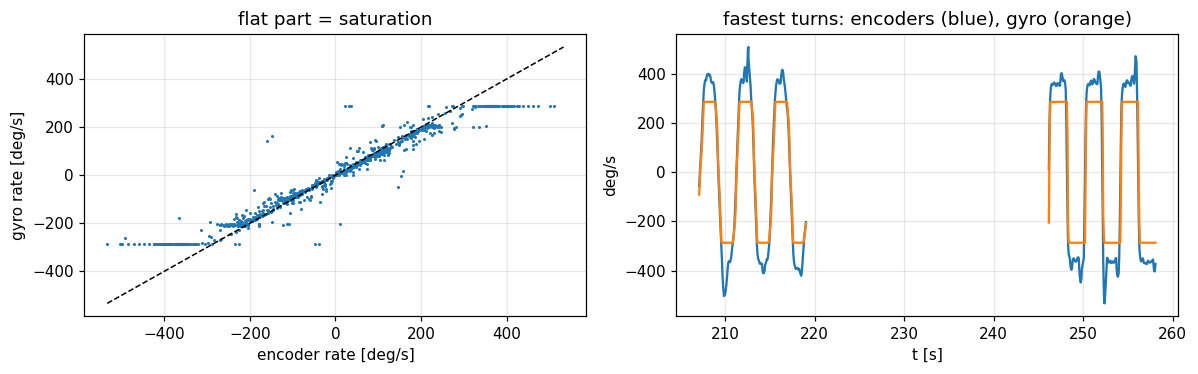

In [ ]:
#measuring wmax
moving = rot[rot.phase.isin(["sin", "rect"])]
raw_max, raw_min = moving.gz_raw.max(), moving.gz_raw.min()
W_MAX = sorted([SIGN * K * raw_max, SIGN * K * raw_min])  #(lowest, highest) deg/s

def longest_stuck(value):                                 #longest run of samples stuck at one value
    stuck = (moving.gz_raw == value).to_numpy().astype(int)
    return max(np.diff(np.flatnonzero(np.r_[1, 1 - stuck, 1])) - 1)

SAT = longest_stuck(raw_max) >= 3 and longest_stuck(raw_min) >= 3

print(f"range {W_MAX[1]:+.1f} / {W_MAX[0]:+.1f} deg/s (raw {raw_max} / {raw_min}): "
      + ("reached, the gyro clipped" if SAT else "NOT reached, spin the robot faster by hand"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].plot(moving.w_enc, moving.w, ".", ms=2)

top = moving.w_enc.abs().max()

ax[0].plot([-top, top], [-top, top], "k--", lw=1)
ax[0].set(xlabel="encoder rate [deg/s]", ylabel="gyro rate [deg/s]", title="flat part = saturation")

for _, g in moving[moving.amp >= 150].groupby((moving.phase != moving.phase.shift()).cumsum()):
    ax[1].plot(g.t, g.w_enc, c="tab:blue")
    ax[1].plot(g.t, g.w, c="tab:orange")

ax[1].set(xlabel="t [s]", ylabel="deg/s", title="fastest turns: encoders (blue), gyro (orange)")
plt.tight_layout()
plt.show()

In [ ]:
#gyro can measure turning only up to about 286 deg/s in each direction
#In the fastest turns the wheels show up to 400–500 deg/s, but the gyro stays stuck at 286
#so it misses part of those turns.

§4: smallest raw step = 1 → Δ = 0.00875 deg/s
§5: σ = 0.0754 deg/s at 16.0 Hz → R = σ² = 5.68e-03
    beyond 3σ: 0.26 % (Gaussian: 0.27 %), biggest 4.1σ


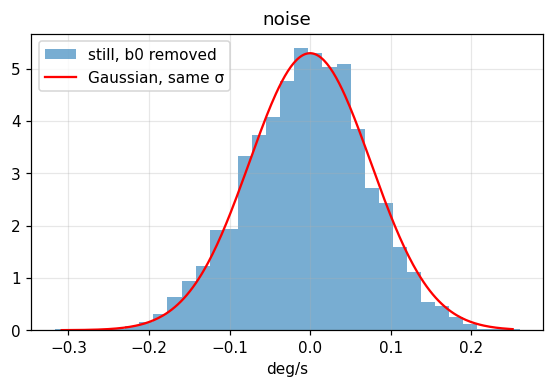

In [ ]:
values = np.unique(static.gz_raw)
D_RAW = np.diff(values).min()
DELTA = D_RAW * abs(K)

print(f"§4: smallest raw step = {D_RAW} → Δ = {DELTA:.5f} deg/s")

noise = static.w - static.w.mean()
SIGMA = noise.std()
outside = 100 * np.mean(np.abs(noise) > 3 * SIGMA)

print(f"§5: σ = {SIGMA:.4f} deg/s at {FS:.1f} Hz → R = σ² = {SIGMA ** 2:.2e}")
print(f"    beyond 3σ: {outside:.2f} % (Gaussian: 0.27 %), biggest {noise.abs().max() / SIGMA:.1f}σ")

plt.figure(figsize=(6, 3.5))
plt.hist(noise, bins=np.arange(noise.min() - DELTA, noise.max() + 2 * DELTA, 2 * DELTA), density=True, alpha=0.6, label="still, b0 removed")

x = np.linspace(noise.min(), noise.max(), 300)

plt.plot(x, norm.pdf(x, 0, SIGMA), "r", label="Gaussian, same σ")
plt.xlabel("deg/s"); plt.title("noise"); plt.legend(); plt.show()

In [ ]:
#When the robot stands still, the gyro readings still jump randomly by about ±0.075 deg/s (σ)
#These jumps follow a normal bell curve with no unusual values

s = -2.53 % left (CCW), -2.53 % right (CW); K = 0.008749; positive = CCW
phase  amp dir  swings  s_pct  clipped
 rect   30 CCW       2  -1.23    False
 rect   30  CW       2  -1.25    False
 rect   60 CCW       3  -2.41    False
 rect   60  CW       4  -3.11    False
 rect  150 CCW       3 -21.22     True
 rect  150  CW       3 -19.60     True
  sin   30 CCW       3  -2.56    False
  sin   30  CW       2  -0.99    False
  sin   60 CCW       3  -3.18    False
  sin   60  CW       3  -2.15    False
  sin  150 CCW       3 -15.14     True
  sin  150  CW       4 -14.06     True


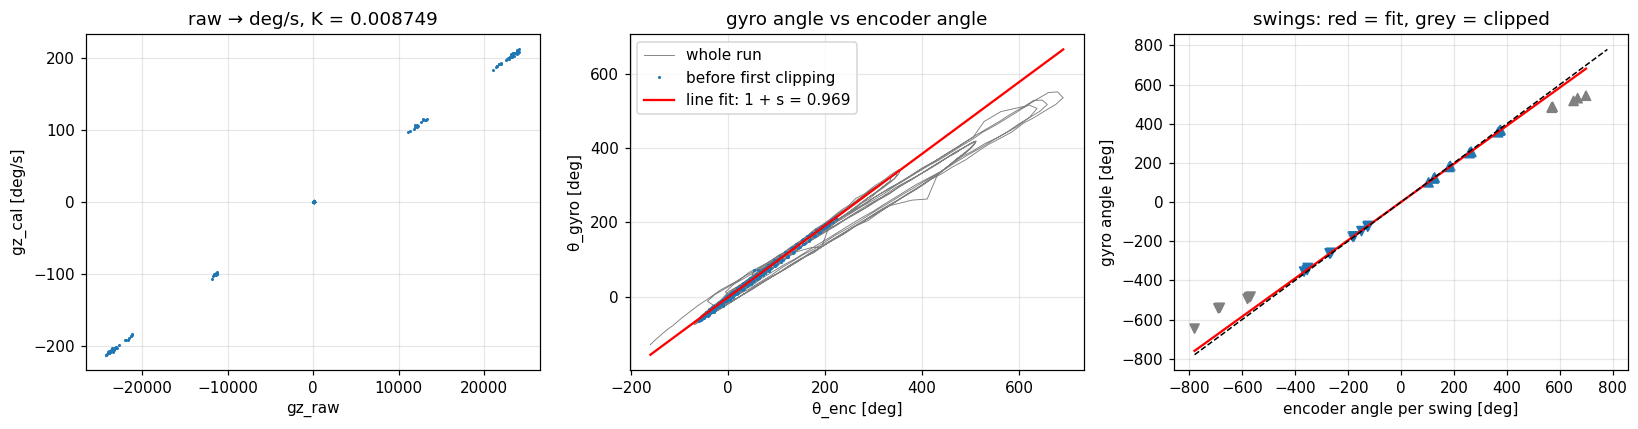

In [ ]:
direction = np.sign(rot.w_enc.to_numpy()) * (rot.w_enc.abs().to_numpy() > 5)   #+1 left, -1 right, 0 still
swings, i = [], 0

while i < len(rot):
    j = i
    while j + 1 < len(rot) and direction[j + 1] == direction[i]:
        j += 1

    g = rot.iloc[i:j + 1]
    turned = g.th_e.iloc[-1] - g.th_e.iloc[0]

    if direction[i] != 0 and g.phase.iloc[0] in ("sin", "rect") and abs(turned) > 5:
        swings.append(dict(phase=g.phase.iloc[0], amp=g.amp.max(), dir="CCW" if direction[i] > 0 else "CW",
                           enc=turned, gyro=g.th_g.iloc[-1] - g.th_g.iloc[0], clipped=(g.gz_raw.abs() > 32000).any()))
    i = j + 1
swings = pd.DataFrame(swings)

def s_percent(x):                                         #slope through 0, minus 1, in %
    return 100 * ((x.enc * x.gyro).sum() / (x.enc ** 2).sum() - 1)

good = swings[~swings.clipped]
S_CCW = s_percent(good[good.dir == "CCW"])
S_CW = s_percent(good[good.dir == "CW"])

print(f"s = {S_CCW:+.2f} % left (CCW), {S_CW:+.2f} % right (CW); K = {K:.6f}; positive = {POS_DIR}")

print(pd.DataFrame([dict(phase=k[0], amp=k[1], dir=k[2], swings=len(x), s_pct=s_percent(x), clipped=x.clipped.any())
                    for k, x in swings.groupby(["phase", "amp", "dir"])]).round(2).to_string(index=False))

first_clip = rot.index[(rot.gz_raw.abs() > 32000).to_numpy()][0]
slow = rot.index < first_clip                            # before the gyro clipped for the first time
fit = np.polyfit(rot.th_e[slow], rot.th_g[slow], 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(raw[steady], cal[steady], ".", ms=2)
ax[0].set(xlabel="gz_raw", ylabel="gz_cal [deg/s]", title=f"raw → deg/s, K = {K:.6f}")
ax[1].plot(rot.th_e, rot.th_g, lw=0.6, c="grey", label="whole run")
ax[1].plot(rot.th_e[slow], rot.th_g[slow], ".", ms=2, label="before first clipping")
xs = np.array([rot.th_e.min(), rot.th_e.max()])
ax[1].plot(xs, np.polyval(fit, xs), "r", label=f"line fit: 1 + s = {fit[0]:.3f}")
ax[1].set(xlabel="θ_enc [deg]", ylabel="θ_gyro [deg]", title="gyro angle vs encoder angle"); ax[1].legend(fontsize=8)

for name, marker, s_val in (("CCW", "^", S_CCW), ("CW", "v", S_CW)):
    x = swings[swings.dir == name]
    ax[2].scatter(x.enc, x.gyro, marker=marker, c=np.where(x.clipped, "grey", "tab:blue"), label=name)
    side = np.array([0, x.enc.abs().max()]) * (1 if name == "CCW" else -1)
    ax[2].plot(side, (1 + s_val / 100) * side, "r")              #fitted slope 1 + s

top = swings.enc.abs().max()

ax[2].plot([-top, top], [-top, top], "k--", lw=1)
ax[2].set(xlabel="encoder angle per swing [deg]", ylabel="gyro angle [deg]", title="swings: red = fit, grey = clipped")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
#The gyro measures about 2.5 % less turning than the wheels, the same for left and right turns.
#In the fastest turns it misses much more, because it reaches its limit

my model    : heading differs from the real gyro by 41.9 deg (RMS)
perfect gyro: heading differs from the real gyro by 58.0 deg (RMS)


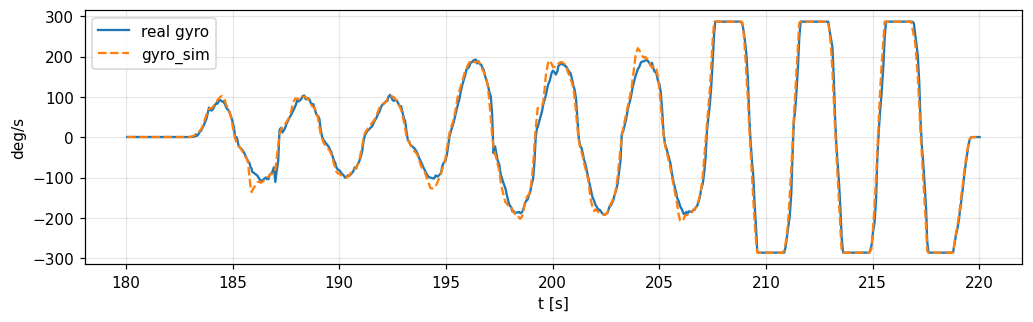

In [ ]:
#Simulated gyro
PARAMS = dict(b0=b0_30, d=d, sigma=SIGMA, delta=DELTA, w_min=W_MAX[0], w_max=W_MAX[1],
              s_ccw=S_CCW / 100, s_cw=S_CW / 100)

def gyro_sim(omega_true, t, p=PARAMS, seed=0):
    """omega_true [deg/s, left = +], t [s from start of the still log] → simulated gyro [deg/s]"""
    omega_true, t = np.asarray(omega_true, float), np.asarray(t, float)

    s = np.where(omega_true >= 0, p["s_ccw"], p["s_cw"])                  #scale factor
    w = (1 + s) * omega_true + p["b0"] + p["d"] / 60 * t                  #+ offset and drift
    w = w + np.random.default_rng(seed).normal(0, p["sigma"], t.shape)    #+ noise
    w = np.clip(w, p["w_min"], p["w_max"])                                #saturation

    return p["delta"] * np.round(w / p["delta"])                          #resolution

t_sim = rot.t.to_numpy() - df.t[static.index[0]]
perfect = dict(PARAMS, s_ccw=0, s_cw=0, w_min=-np.inf, w_max=np.inf, delta=1e-9)

for name, p in (("my model", PARAMS), ("perfect gyro", perfect)):
    heading = integrate(gyro_sim(rot.w_enc, t_sim, p) - b0_fresh, rot.t, initial=0)
    print(f"{name:12s}: heading differs from the real gyro by {np.sqrt(np.mean((heading - rot.th_g) ** 2)):.1f} deg (RMS)")

first40 = rot.t < rot.t.iloc[0] + 40
plt.figure(figsize=(11, 3))
plt.plot(rot.t[first40], rot.w[first40], label="real gyro")
plt.plot(rot.t[first40], gyro_sim(rot.w_enc, t_sim)[first40], "--", label="gyro_sim")
plt.xlabel("t [s]")
plt.ylabel("deg/s")
plt.legend()
plt.show()

In [ ]:
#My simulated gyro behaves like the real one
#it follows the same turns and stops at the same limit of 286 deg/s
#Its heading is closer to the real gyro than a perfect gyro would be (42° vs 58°)

In [ ]:
#heading error(deg) from each souce
budget = pd.DataFrame({f"{t} s": {
    "offset, not removed": abs(b0_30) * t,
    "offset left after calibrate_gyro": ERR_LEFT * t / 60,
    "drift": 0.5 * abs(d) / 60 * t ** 2,
    "noise": SIGMA * np.sqrt(t / FS)} for t in (10, 60, 180)})
print(budget.round(2).to_string())
print("biggest after calibration:", {c: budget.drop("offset, not removed")[c].idxmax() for c in budget.columns})
print(f"scale factor: {max(abs(S_CCW), abs(S_CW)) * 3.6:.1f} deg per full turn; above {W_MAX[1]:.0f} deg/s the gyro clips and loses far more")

                                  10 s   60 s  180 s
offset, not removed               4.68  28.09  84.26
offset left after calibrate_gyro  0.20   1.20   3.60
drift                             0.00   0.01   0.09
noise                             0.06   0.15   0.25
biggest after calibration: {'10 s': 'offset left after calibrate_gyro', '60 s': 'offset left after calibrate_gyro', '180 s': 'offset left after calibrate_gyro'}
scale factor: 9.1 deg per full turn; above 287 deg/s the gyro clips and loses far more


In [ ]:
#Without calibration, the offset makes the heading wrong by 84° after 3 minutes
#After calibration only about 4° is left, and drift and noise add less than 1°
#When the robot turns, it loses about 9° per full turn, and much more if it turns faster than 287 deg/s.

In [ ]:
#Parameter table
table = pd.DataFrame([
    ["Offset (bias)", "b0", f"{b0_30:+.4f} ± {se_30:.4f}", "deg/s", f"still mean, T = 30 s (calibrate_gyro: {b0_cal:+.4f}, T = {T_CAL} s)"],
    ["Bias drift", "d", f"{d:+.4f}", "deg/s/min", "30-s window means"],
    ["Heading drift, uncorrected", "", f"{HEAD_DRIFT:+.1f}", "deg/min", "slope of θ(t)"],
    ["Measurement range", "±ω_max", f"{W_MAX[1]:+.1f} / {W_MAX[0]:+.1f}" + ("" if SAT else " (not reached)"), "deg/s", "saturation test"],
    ["Resolution", "Δ", f"{DELTA:.5f}", "deg/s", "smallest raw step"],
    ["Noise std", "σ", f"{SIGMA:.4f}", "deg/s", f"still, 3 min, at {FS:.1f} Hz"],
    ["Raw → deg/s factor", "K", f"{K:.6f}", "deg/s per raw", "read() vs readRawData()"],
    ["Scale-factor error CCW / CW", "s", f"{S_CCW:+.2f} / {S_CW:+.2f}", "%", "gyro vs encoder angle per swing"],
    ["Positive rotation direction", "", POS_DIR, "—", "gyro vs encoder sign"],
], columns=["Parameter", "Symbol", "Value", "Unit", "Method"])

display(table)

json.dump({**{k: float(v) for k, v in PARAMS.items()}, "K": float(K), "sign": SIGN, "fs": float(FS), "R": float(SIGMA ** 2)},
          open("lab9_gyro_params.json", "w"), indent=1)        #for Labs 10–12

,Parameter,Symbol,Value,Unit,Method
0,Offset (bias),b0,+0.4681 ± 0.0032,deg/s,"still mean, T = 30 s (calibrate_gyro: +0.4681,..."
1,Bias drift,d,+0.0003,deg/s/min,30-s window means
2,"Heading drift, uncorrected",,+27.2,deg/min,slope of θ(t)
3,Measurement range,±ω_max,+286.7 / -286.4,deg/s,saturation test
4,Resolution,Δ,0.00875,deg/s,smallest raw step
5,Noise std,σ,0.0754,deg/s,"still, 3 min, at 16.0 Hz"
6,Raw → deg/s factor,K,0.008749,deg/s per raw,read() vs readRawData()
7,Scale-factor error CCW / CW,s,-2.53 / -2.53,%,gyro vs encoder angle per swing
8,Positive rotation direction,,CCW,—,gyro vs encoder sign


In [ ]:
#Conclusion:
#At rest the gyro should read 0, but it reads 0.47 deg/s. This error (the offset) makes the heading 84° wrong after 3 minutes.
#A 30-second calibration removes that, leaving only about 4° of error. Drift and noise are very small.
#When turning, the gyro shows 2.5 % less than the wheels and can't measure faster than 286 deg/s
#so it misses part of the fastest turns (30° difference at the end).